# Diagnostic Table — All 4 Policies

Rows: diagnostic outcomes (wait times and mortality per phase).
Columns: the 4 policy combinations.
Median [Q25, Q75].

In [4]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

Loaded 98304 runs


In [9]:
policies = [
    ("Stovepipe",  0, 0),
    ("Amb only",   0, 1),
    ("Fac only",   1, 0),
    ("Both",       1, 1),
]

rows = [
    ("Median wait: CCP transport (T1)",  "median_wait_ccp_transport_T1"),
    ("Mortality: CCP transport (T1)",    "mortality_ccp_transport_T1"),
    ("Median wait: R1 care (T1)",        "median_wait_r1_care_T1"),
    ("Mortality: R1 care (T1)",          "mortality_r1_care_T1"),
    # ("Median wait: R1 transport (T1)",   "median_wait_r1_transport_T1"),
    # ("Mortality: R1 transport (T1)",     "mortality_r1_transport_T1"),
    # ("Median wait: R2 care (T1)",        "median_wait_r2_care_T1"),
    # ("Mortality: R2 care (T1)",          "mortality_r2_care_T1"),
    ("Death rate T1 BCAS",               "death_rate_T1_BCAS"),
]

policy_dfs = {}
for label, fac, amb in policies:
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]
    policy_dfs[label] = sub

col_names = [f"{label}\nn={len(policy_dfs[label])}" for label, _, _ in policies]
row_names = [r[0] for r in rows]

matrix = pd.DataFrame(index=row_names, columns=col_names, dtype=float)
q25_mat = pd.DataFrame(index=row_names, columns=col_names, dtype=float)
q75_mat = pd.DataFrame(index=row_names, columns=col_names, dtype=float)

for (label, fac, amb), col_name in zip(policies, col_names):
    sub = policy_dfs[label]
    for row_label, outcome in rows:
        vals = sub[outcome].dropna().values
        matrix.loc[row_label, col_name] = np.median(vals) if len(vals) > 0 else np.nan
        q25_mat.loc[row_label, col_name] = np.percentile(vals, 25) if len(vals) > 0 else np.nan
        q75_mat.loc[row_label, col_name] = np.percentile(vals, 75) if len(vals) > 0 else np.nan

print(matrix.to_string(float_format="%.4f"))

                                 Stovepipe\nn=24576  Amb only\nn=24576  Fac only\nn=24576  Both\nn=24576
Median wait: CCP transport (T1)             15.0000            23.0000            15.0000        22.8420
Mortality: CCP transport (T1)                0.6000             0.0000             0.6000         0.0000
Median wait: R1 care (T1)                    0.0000             0.0000             0.0000         0.0000
Mortality: R1 care (T1)                      0.0000             0.0000             0.0000         0.0000
Death rate T1 BCAS                           0.6000             0.0000             0.6000         0.0000


## Heatmap

C:\Users\User\AppData\Local\Temp\ipykernel_32904\1166428158.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


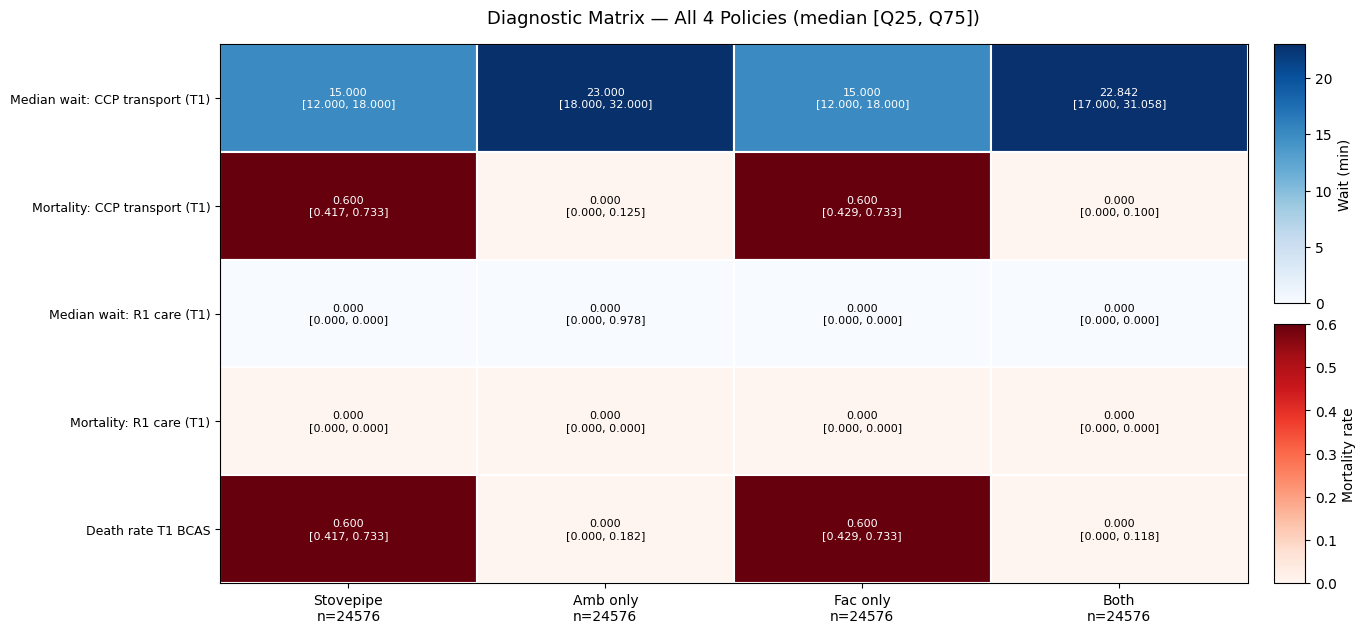

In [10]:
wait_idx = [i for i, (lab, _) in enumerate(rows) if lab.startswith("Median wait")]
mort_idx = [i for i, (lab, _) in enumerate(rows) if lab.startswith("Mortality") or lab.startswith("Death rate")]

vals_f = matrix.values.astype(float)
wait_vals = vals_f[wait_idx, :].flatten()
mort_vals = vals_f[mort_idx, :].flatten()
norm_wait = Normalize(vmin=np.nanmin(wait_vals), vmax=max(np.nanmax(wait_vals), 0.01))
norm_mort = Normalize(vmin=np.nanmin(mort_vals), vmax=max(np.nanmax(mort_vals), 0.01))
cmap_wait = plt.cm.Blues
cmap_mort = plt.cm.Reds

n_rows, n_cols = vals_f.shape

fig = plt.figure(figsize=(14, n_rows * 1.0 + 2))
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1],
                       wspace=0.05, hspace=0.08)
ax = fig.add_subplot(gs[:, 0])
cax_w = fig.add_subplot(gs[0, 1])
cax_m = fig.add_subplot(gs[1, 1])

for i in range(n_rows):
    is_mort = i in mort_idx
    norm = norm_mort if is_mort else norm_wait
    cmap = cmap_mort if is_mort else cmap_wait
    for j in range(n_cols):
        v = vals_f[i, j]
        color = cmap(norm(v)) if not np.isnan(v) else (0.95, 0.95, 0.95, 1)
        ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                    facecolor=color, edgecolor="white", lw=1.5))
        if not np.isnan(v):
            q25 = q25_mat.iloc[i, j]
            q75 = q75_mat.iloc[i, j]
            txt = f"{v:.3f}\n[{q25:.3f}, {q75:.3f}]"
            brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if brightness < 0.55 else "black")

ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(n_rows - 0.5, -0.5)
ax.set_xticks(range(n_cols))
ax.set_xticklabels(col_names, fontsize=10)
ax.set_yticks(range(n_rows))
ax.set_yticklabels(row_names, fontsize=9)
ax.set_title("Diagnostic Matrix — All 4 Policies (median [Q25, Q75])", fontsize=13, pad=15)

fig.colorbar(ScalarMappable(norm=norm_wait, cmap=cmap_wait), cax=cax_w, label="Wait (min)")
fig.colorbar(ScalarMappable(norm=norm_mort, cmap=cmap_mort), cax=cax_m, label="Mortality rate")

plt.tight_layout()
plt.show()